# 외식업 10종 GEE 보조분석

종로구·마포구의 공개자료 외식업 10종, 2023~2025년 12개 **분기**에서 500m 내 알려진 공연 활동과 매출의 관계를 탐색한다. 최종 04번의 확장 패널을 입력으로 사용하고, 최종 05번 FE 주분석의 업종별 기울기와 비교한다. 기존 두 업종 결과를 본 뒤 범위를 넓힌 **탐색적 확장**이며, 사전에 등록한 확인적 검정이나 원논문을 그대로 재현한 분석이 아니다.

기존 두 업종 기준선과 같은 Gaussian identity / exchangeable / 상권 군집 robust GEE를 10종으로 확장한다. 관측된 상권×업종의 평균 공연 활동(`between`)과 그 평균에서의 분기별 편차(`within`)를 분리한다. GEE는 상권×업종 고정효과가 없고 자치구만 통제하므로, FE와의 차이는 평균구조와 추정법 차이가 함께 반영된 것이다. 인과효과를 입증하지 않는다.

**실행 순서:** 최종 04 → 05 → 06. 04 산출물로 GEE를 추정하고 05 결과와 비교한다. 결과 파일의 `10_` 접두사는 도구 호환성을 위해 유지한다. 모든 계산은 로컬 파일로 수행하며 인터넷/API를 호출하지 않는다. 산출물은 `results/main/baseline/`에 저장한다.

In [1]:
from pathlib import Path
import os
for variable in ['OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'OMP_NUM_THREADS']:
    os.environ[variable] = '1'
import json, hashlib, warnings, platform, inspect
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'AGENTS.md').is_file() and (p / 'data/raw').is_dir())
DATA, REPORTS = ROOT / 'data/analysis/final', ROOT / 'results/main/baseline'
FIGURES = REPORTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
INPUT = DATA / 'food_industry_panel.csv'
CATALOG = DATA / 'food_industry_catalog.csv'
input_hashes = {p.relative_to(ROOT).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in [INPUT, CATALOG]}

### 고정 입력 읽기
최종 패널과 업종 사전을 읽고 해시를 기록한다. 실행 중인 수집 파일이나 네트워크를 사용하지 않는다.

In [2]:
panel = pd.read_csv(INPUT, dtype={'area_id': str, 'industry_id': str, 'quarter': str})
catalog = pd.read_csv(CATALOG, dtype={'industry_id': str}).sort_values('industry_id')
INDUSTRIES = catalog['industry_id'].tolist()
LABELS = catalog.set_index('industry_id')['industry'].to_dict()
QUARTERS = [f'{year}{q}' for year in range(2023, 2026) for q in range(1, 5)]
OUTCOMES = {'log_sales': '총매출 log(1+원)', 'night_share_pct': '21~24시 매출 비중(%p)'}
KEY = ['area_id', 'industry_id', 'quarter']
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

## 1. 입력과 분석 단위
공개자료의 코드 CS100001~CS100010을 모두 유지한다. 총매출이 누락된 관측을 0원으로 바꾸지 않는다. 총매출 결과는 관측된 0원도 포함하되 음수는 제외하고, 야간 비중은 총매출이 양수이며 0≤야간매출≤총매출인 경우만 정의한다. 공연 수는 공연 ID가 해당 분기에 활동한 목록 수로, 공연 회차·관객·티켓 매출이나 일별 활동량이 아니다.

In [3]:
assert set(INDUSTRIES) == {f'CS100{i:03d}' for i in range(1, 11)}
assert len(INDUSTRIES) == 10 and not panel.duplicated(KEY).any()
assert set(panel['industry_id']) == set(INDUSTRIES)
assert set(panel['quarter']) == set(QUARTERS)
assert set(panel['district']) == {'종로구', '마포구'}
for column in ['total_sales', 'night_sales', 'known_performance_count_500m']:
    panel[column] = pd.to_numeric(panel[column], errors='raise')
panel['entity'] = panel['area_id'] + '|' + panel['industry_id']
valid_sales = np.isfinite(panel['total_sales']) & panel['total_sales'].ge(0)
valid_night = (np.isfinite(panel['night_sales']) & panel['total_sales'].gt(0)
               & panel['night_sales'].ge(0) & panel['night_sales'].le(panel['total_sales'])
               & valid_sales)
valid_activity = (np.isfinite(panel['known_performance_count_500m'])
                  & panel['known_performance_count_500m'].ge(0))
panel['log_sales'] = np.log1p(panel['total_sales'].where(valid_sales))
panel['night_share_pct'] = (100 * panel['night_sales'] / panel['total_sales']).where(valid_night)
panel['log_activity'] = np.log1p(panel['known_performance_count_500m'].where(valid_activity))
coverage = panel.groupby('industry_id').agg(
    panel_rows=('quarter', 'size'), observed_sales=('total_sales', 'count'),
    valid_log_sales=('log_sales', 'count'), valid_night_share=('night_share_pct', 'count'))
coverage.insert(0, 'industry', coverage.index.map(LABELS))
display(coverage)

,industry,panel_rows,observed_sales,valid_log_sales,valid_night_share
industry_id,,,,,
CS100001,한식음식점,1812,1489,1489,1489
CS100002,중식음식점,1812,464,464,464
CS100003,일식음식점,1812,479,479,479
CS100004,양식음식점,1812,660,660,660
CS100005,제과점,1812,534,534,534
CS100006,패스트푸드점,1812,446,446,446
CS100007,치킨전문점,1812,480,480,480
CS100008,분식전문점,1812,857,857,857
CS100009,호프-간이주점,1812,944,944,944


**표 해석:** 같은 상권·분기라도 업종별 매출 제공 여부가 다르다. 결과변수마다 이용 가능한 표본을 별도로 만들며, 균형 패널이나 모든 업종이 동시에 관측된 표본으로 임의 축소하지 않는다. 이 때문에 업종 간 기울기 비교에는 표본 구성 차이도 포함된다.

## 2. 추정 가능성 기준과 표본 흐름
결과변수·공연 활동·자치구·분기가 유효한 완전 사례에서 출발해, 최소 두 분기가 관측된 상권×업종만 남긴다. 각 업종은 최소 20개 상권 군집과 0이 아닌 공연 활동의 시간 내 잔차 변동이 있어야 한다. 잔차는 상권 평균을 제거한 공연 활동을, 상권 평균이 제거된 분기 더미에 회귀해 계산한다. 이는 업종별 상권·분기 고정효과를 모두 제거한 변동을 확인하는 절차다.

이 기준은 정보가 없는 업종을 식별하려는 하한이며, 20개 군집만으로 정규 근사의 정확성이 보장되지는 않는다. 분석 가능성을 모든 10개 업종·두 결과에 대해 기록한다.

In [4]:
def residual_activity(frame):
    grouped = frame.groupby('entity', sort=False)
    within_x = frame['log_activity'] - grouped['log_activity'].transform('mean')
    quarter = pd.get_dummies(pd.Categorical(frame['quarter'], categories=QUARTERS),
                             drop_first=True, dtype=float)
    quarter.index = frame.index
    within_quarter = quarter - quarter.groupby(frame['entity']).transform('mean')
    fitted = within_quarter.to_numpy() @ np.linalg.lstsq(
        within_quarter.to_numpy(), within_x.to_numpy(), rcond=None)[0]
    return within_x.to_numpy() - fitted

frames, flow_rows, eligibility_rows = {}, [], []
for outcome in OUTCOMES:
    complete = (np.isfinite(panel[outcome]) & np.isfinite(panel['log_activity'])
                & panel[['area_id', 'industry_id', 'district', 'quarter']].notna().all(axis=1))
    complete_frame = panel.loc[complete].copy()
    counts = complete_frame.groupby('entity')['quarter'].transform('nunique')
    repeated = complete_frame.loc[counts.ge(2)].copy()
    eligible_ids = []
    for industry_id in INDUSTRIES:
        subset = repeated.loc[repeated['industry_id'].eq(industry_id)]
        residual = residual_activity(subset) if len(subset) else np.array([])
        residual_sd = float(np.sqrt(np.mean(residual ** 2))) if len(residual) else np.nan
        clusters = int(subset['area_id'].nunique())
        eligible = bool(clusters >= 20 and np.isfinite(residual_sd) and residual_sd > 1e-10)
        reason = '추정 가능' if eligible else ('상권 20개 미만' if clusters < 20 else '시간 내 잔차변동 없음')
        eligibility_rows.append(dict(outcome=outcome, industry_id=industry_id,
            industry=LABELS[industry_id], nobs_industry=len(subset), area_clusters_industry=clusters,
            residual_activity_rms=residual_sd, eligible=eligible, reason=reason))
        if eligible:
            eligible_ids.append(industry_id)
    frames[outcome] = repeated.loc[repeated['industry_id'].isin(eligible_ids)].copy()
    for step, frame in [('panel', panel), ('complete_cases', complete_frame),
                        ('entity_at_least_2_quarters', repeated), ('eligible_industries', frames[outcome])]:
        flow_rows.append(dict(outcome=outcome, step=step, nobs=len(frame),
            entities=frame['entity'].nunique(), area_clusters=frame['area_id'].nunique(),
            industries=frame['industry_id'].nunique()))
eligibility = pd.DataFrame(eligibility_rows)
sample_flow = pd.DataFrame(flow_rows)
display(sample_flow)
display(eligibility[['outcome', 'industry', 'nobs_industry', 'area_clusters_industry',
                     'residual_activity_rms', 'eligible', 'reason']])

,outcome,step,nobs,entities,area_clusters,industries
0,log_sales,panel,18120,1510,151,10
1,log_sales,complete_cases,7661,693,135,10
2,log_sales,entity_at_least_2_quarters,7646,678,134,10
3,log_sales,eligible_industries,7646,678,134,10
4,night_share_pct,panel,18120,1510,151,10
5,night_share_pct,complete_cases,7661,693,135,10
6,night_share_pct,entity_at_least_2_quarters,7646,678,134,10
7,night_share_pct,eligible_industries,7646,678,134,10


,outcome,industry,nobs_industry,area_clusters_industry,residual_activity_rms,eligible,reason
0,log_sales,한식음식점,1488,126,0.3941,True,추정 가능
1,log_sales,중식음식점,458,43,0.3381,True,추정 가능
2,log_sales,일식음식점,479,43,0.3026,True,추정 가능
3,log_sales,양식음식점,658,59,0.3275,True,추정 가능
4,log_sales,제과점,534,48,0.3550,True,추정 가능
5,log_sales,패스트푸드점,445,40,0.3570,True,추정 가능
6,log_sales,치킨전문점,479,45,0.3659,True,추정 가능
7,log_sales,분식전문점,854,76,0.3775,True,추정 가능
8,log_sales,호프-간이주점,944,83,0.3741,True,추정 가능
9,log_sales,커피-음료,1307,115,0.3936,True,추정 가능


**표 해석:** `eligible`은 모형에 들어갈 최소 정보의 충족 여부다. 실제 추정 성공 여부는 아래의 설계행렬·수렴·공분산 진단을 추가로 통과해야 한다. 제외된 업종을 다른 모형으로 자동 대체하거나, 유의한 결과가 나오는 표본을 고르지 않는다.

## 3. 최종 표본에서 within–between 분해
결과변수별 최종 표본에서 상권×업종별 `log(1+공연 수)` 평균을 `between_activity`, 각 관측에서 그 평균을 뺀 값을 `within_activity`로 정의한다. 결측으로 관측 분기가 다르면 같은 상권의 업종별 평균도 달라질 수 있다.

업종별로 **절편 + 마포구 지시변수 + 분기 더미 11개 + within + between**의 15개 계수를 둔다. 모든 업종이 가능하면 총 150열이다. 종로구와 2023년 1분기가 기준이다. 상권×업종 고정효과를 추가하면 `between`과 중복되므로 이 GEE에는 넣지 않는다. 점포 수 통제는 포함하지 않는다.

In [5]:
def make_design(frame):
    frame = frame.sort_values(['area_id', 'industry_id', 'quarter']).reset_index(drop=True).copy()
    frame['between_activity'] = frame.groupby('entity')['log_activity'].transform('mean')
    frame['within_activity'] = frame['log_activity'] - frame['between_activity']
    columns = {}
    for industry_id in INDUSTRIES:
        if not frame['industry_id'].eq(industry_id).any():
            continue
        indicator = frame['industry_id'].eq(industry_id).astype(float)
        columns[f'{industry_id}:intercept'] = indicator
        columns[f'{industry_id}:mapo'] = indicator * frame['district'].eq('마포구')
        for quarter in QUARTERS[1:]:
            columns[f'{industry_id}:quarter_{quarter}'] = indicator * frame['quarter'].eq(quarter)
        columns[f'{industry_id}:within'] = indicator * frame['within_activity']
        columns[f'{industry_id}:between'] = indicator * frame['between_activity']
    design = pd.DataFrame(columns, index=frame.index, dtype=float)
    return frame, design

designs, decomposition_rows = {}, []
for outcome, frame in frames.items():
    if frame.empty:
        continue
    frames[outcome], designs[outcome] = make_design(frame)
    sample = frames[outcome]
    mean_error = sample.groupby('entity')['within_activity'].mean().abs().max()
    identity_error = (sample['log_activity'] - sample['within_activity'] - sample['between_activity']).abs().max()
    assert mean_error < 1e-10 and identity_error < 1e-10
    decomposition_rows.append(dict(outcome=outcome, within_mean_max_abs=mean_error,
        decomposition_max_abs=identity_error, design_columns=designs[outcome].shape[1]))
display(pd.DataFrame(decomposition_rows))

,outcome,within_mean_max_abs,decomposition_max_abs,design_columns
0,log_sales,0.0000,0.0000,150
1,night_share_pct,0.0000,0.0000,150


**표 해석:** 두 오차가 수치적 0이면 최종 관측 표본의 평균과 편차가 정확히 분리되었다. `within`은 한 상권×업종의 평균보다 공연 활동이 높은 분기와 매출의 관계다. `between`은 관측기간 평균 활동이 다른 상권×업종의 차이이므로, 지역의 미관측 특성과 상권 규모가 섞일 가능성이 더 크다.

## 4. GEE 추정과 수용 기준
하나의 상권 안에 있는 **모든 업종과 분기**를 한 군집으로 묶는다. Exchangeable 작업상관은 같은 상권의 관측쌍에 공통 상관계수 α를 사용한다. 추론은 상권별 score를 합친 robust sandwich 공분산과 정규 근사 95% 구간을 사용한다. 이는 다른 상권 간 공간 상관을 해결하지 않는다.

설계행렬의 완전 열순위, 수렴, 유한한 모든 계수·표준오차·공분산·α, 양수 표준오차를 확인한다. 최대 군집 크기 m에서 `1−α>0` 및 `1+(m−1)α>0`도 확인한다. 어느 조건이든 실패하면 해당 결과의 기울기를 보고하지 않고 진단만 남긴다. 자동 fallback은 하지 않는다.

In [6]:
def fit_checked(outcome, frame, design):
    diag = dict(outcome=outcome, nobs=len(frame), area_clusters=frame['area_id'].nunique(),
        industries=frame['industry_id'].nunique(), design_columns=design.shape[1],
        design_rank=int(np.linalg.matrix_rank(design.to_numpy())), accepted=False,
        converged=False, alpha=np.nan, max_cluster_size=int(frame.groupby('area_id').size().max()),
        eigenvalue_1_minus_alpha=np.nan, eigenvalue_cluster_mean=np.nan,
        finite_params=False, finite_standard_errors=False, finite_covariance=False,
        positive_standard_errors=False, warnings='', failure_reason='')
    if diag['design_rank'] != diag['design_columns']:
        diag['failure_reason'] = 'design_not_full_column_rank'
        return None, diag
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model = sm.GEE(frame[outcome], design, groups=frame['area_id'],
                family=sm.families.Gaussian(link=sm.families.links.Identity()),
                cov_struct=sm.cov_struct.Exchangeable(), missing='raise')
            fit = model.fit(maxiter=100, ctol=1e-8, cov_type='robust')
        alpha = float(fit.cov_struct.dep_params)
        diag.update(converged=bool(fit.converged), alpha=alpha,
            eigenvalue_1_minus_alpha=1-alpha,
            eigenvalue_cluster_mean=1+(diag['max_cluster_size']-1)*alpha,
            finite_params=bool(np.isfinite(fit.params).all()),
            finite_standard_errors=bool(np.isfinite(fit.bse).all()),
            finite_covariance=bool(np.isfinite(fit.cov_params()).all().all()),
            positive_standard_errors=bool((fit.bse > 0).all()),
            warnings=' | '.join(str(item.message) for item in caught))
        diag['accepted'] = bool(diag['converged'] and np.isfinite(alpha)
            and diag['eigenvalue_1_minus_alpha'] > 0 and diag['eigenvalue_cluster_mean'] > 0
            and all(diag[key] for key in ['finite_params', 'finite_standard_errors',
                                         'finite_covariance', 'positive_standard_errors']))
        if not diag['accepted']:
            diag['failure_reason'] = 'convergence_or_covariance_acceptance_failed'
        return (fit if diag['accepted'] else None), diag
    except Exception as error:
        diag['failure_reason'] = f'{type(error).__name__}: {error}'
        return None, diag

In [7]:
models, diagnostics = {}, []
for outcome in OUTCOMES:
    if outcome not in designs:
        diagnostics.append(dict(outcome=outcome, accepted=False, failure_reason='no_eligible_industries'))
        continue
    fit, diag = fit_checked(outcome, frames[outcome], designs[outcome])
    diagnostics.append(diag)
    if fit is not None:
        models[outcome] = fit
diagnostics = pd.DataFrame(diagnostics)
display(diagnostics[['outcome', 'nobs', 'area_clusters', 'design_rank', 'design_columns',
                     'converged', 'alpha', 'max_cluster_size', 'accepted']])
display(diagnostics[['outcome', 'eigenvalue_1_minus_alpha', 'eigenvalue_cluster_mean',
                     'finite_params', 'finite_standard_errors', 'finite_covariance',
                     'positive_standard_errors', 'warnings', 'failure_reason']])

,outcome,nobs,area_clusters,design_rank,design_columns,converged,alpha,max_cluster_size,accepted
0,log_sales,7646,134,150,150,True,0.8249,120,True
1,night_share_pct,7646,134,150,150,True,0.1834,120,True


,outcome,eigenvalue_1_minus_alpha,eigenvalue_cluster_mean,finite_params,finite_standard_errors,finite_covariance,positive_standard_errors,warnings,failure_reason
0,log_sales,0.1751,99.1657,True,True,True,True,,
1,night_share_pct,0.8166,22.8237,True,True,True,True,,


**진단 해석:** `accepted=True`는 위의 수치적 수용 조건을 충족했다는 뜻이다. 모형 가정의 진실성이나 인과적 식별의 성공을 뜻하지 않는다. 같은 상권 내 상관은 보정하지만 상권 경계 중복·인접 상권의 공동 충격은 남을 수 있다.

## 5. 업종별 within 기울기와 탐색적 다중검정
계수는 `log(1+500m 내 알려진 공연 수)`가 1 증가할 때의 결과변수 차이다. 총매출 계수는 log(1+원) 단위이며, 야간 비중 계수는 **퍼센트포인트(%p)** 단위다. 공연 수가 0에서 1로 늘 때는 해당 계수에 `log(2)`를 곱한다. 이를 공연 1회당 효과로 해석하지 않는다.

10개 업종×2개 결과의 GEE within 기울기 20개에 별도의 Benjamini–Hochberg 보정을 적용한다. 추정 실패 항목의 p값을 1로 놓은 계획된 20개 검정 집합을 사용하고, 실패한 기울기는 여전히 결측으로 표시한다. 이 보정은 **보조분석 안의 탐색적 보정**이며 최종 05번 FE의 20개 기본 검정과 별개다. FE와 GEE 중 더 유의한 모형을 선택하지 않는다.

다중검정 보정은 p값에 적용한다. 아래 그림의 **95% 신뢰구간은 개별 정규 근사 구간이며 다중비교 보정 구간이 아니다.**

In [8]:
rows = []
for outcome in OUTCOMES:
    frame, fit = frames[outcome], models.get(outcome)
    for industry_id in INDUSTRIES:
        sample = frame.loc[frame['industry_id'].eq(industry_id)]
        for component in ['within', 'between']:
            term = f'{industry_id}:{component}'
            estimated = fit is not None and term in fit.params.index
            beta = float(fit.params[term]) if estimated else np.nan
            se = float(fit.bse[term]) if estimated else np.nan
            z = beta / se if estimated else np.nan
            rows.append(dict(scenario='gee_within_between_500', outcome=outcome,
                industry_id=industry_id, industry=LABELS[industry_id], component=component,
                coefficient=beta, standard_error=se, ci_low=beta-norm.ppf(.975)*se,
                ci_high=beta+norm.ppf(.975)*se, p_value=2*norm.sf(abs(z)),
                estimated=estimated, nobs_industry=len(sample),
                area_clusters_industry=sample['area_id'].nunique(), nobs_total=len(frame),
                area_clusters_total=frame['area_id'].nunique()))
all_effects = pd.DataFrame(rows)
within = all_effects.loc[all_effects['component'].eq('within')].copy()
between = all_effects.loc[all_effects['component'].eq('between')].copy()
assert len(within) == 20
within['p_fdr_gee_exploratory'] = multipletests(within['p_value'].fillna(1), method='fdr_bh')[1]
within.loc[~within['estimated'], 'p_fdr_gee_exploratory'] = np.nan
display(within[['outcome', 'industry', 'coefficient', 'ci_low', 'ci_high', 'p_value',
                'p_fdr_gee_exploratory', 'nobs_industry', 'area_clusters_industry', 'estimated']])

,outcome,industry,coefficient,ci_low,ci_high,p_value,p_fdr_gee_exploratory,nobs_industry,area_clusters_industry,estimated
0,log_sales,한식음식점,-0.0082,-0.0703,0.0539,0.7951,0.8370,1488,126,True
2,log_sales,중식음식점,-0.0195,-0.1537,0.1147,0.7757,0.8370,458,43,True
4,log_sales,일식음식점,-0.0375,-0.1847,0.1098,0.6179,0.8066,479,43,True
6,log_sales,양식음식점,0.0623,-0.0791,0.2037,0.3878,0.8066,658,59,True
8,log_sales,제과점,-0.0323,-0.1623,0.0976,0.6257,0.8066,534,48,True
10,log_sales,패스트푸드점,0.0398,-0.1297,0.2094,0.6453,0.8066,445,40,True
12,log_sales,치킨전문점,-0.0505,-0.2022,0.1013,0.5147,0.8066,479,45,True
14,log_sales,분식전문점,-0.0225,-0.1043,0.0592,0.5893,0.8066,854,76,True
16,log_sales,호프-간이주점,0.0037,-0.0772,0.0847,0.9284,0.9284,944,83,True
18,log_sales,커피-음료,-0.0173,-0.1142,0.0797,0.7269,0.8370,1307,115,True


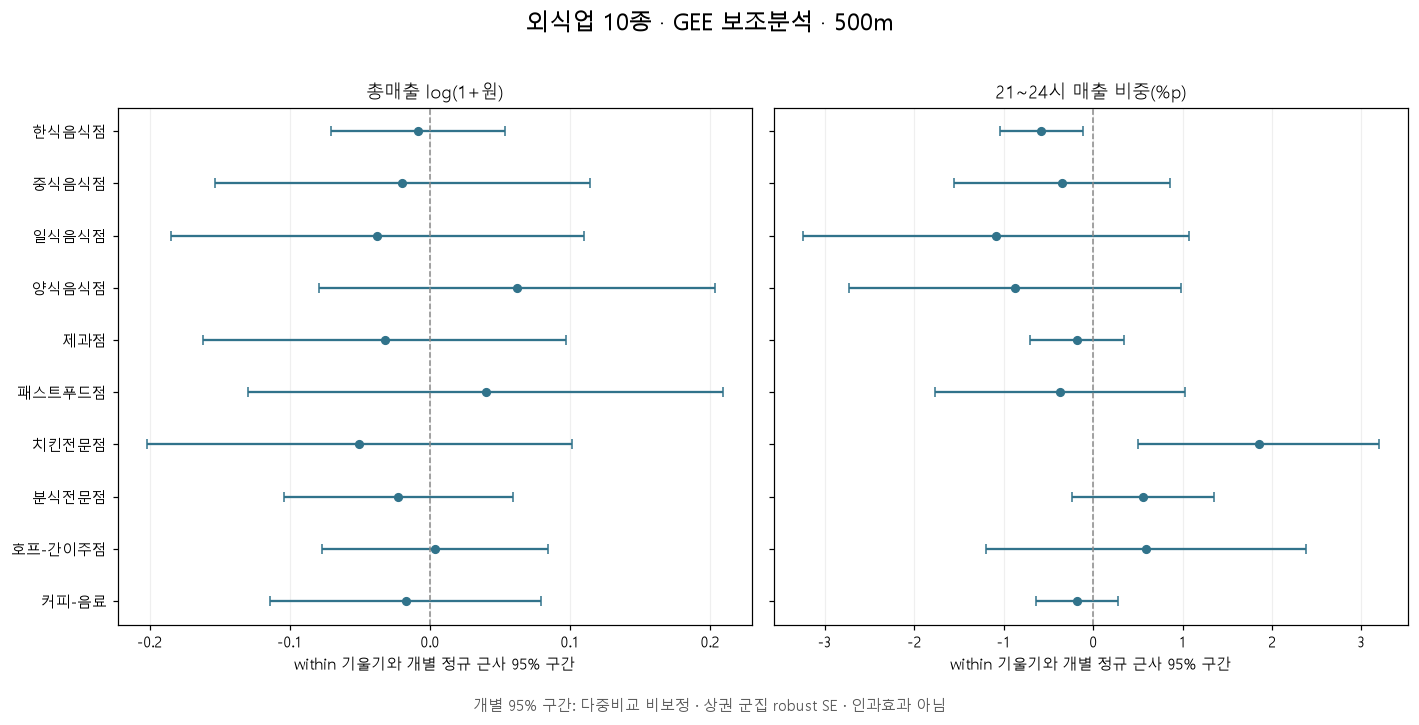

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
font_names = {font.name for font in fm.fontManager.ttflist}
plt.rcParams['font.family'] = next((font for font in ['Malgun Gothic', 'NanumGothic', 'AppleGothic']
                                  if font in font_names), 'DejaVu Sans')
plt.rcParams.update({'axes.unicode_minus': False, 'font.size': 10, 'figure.dpi': 110})
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6), sharey=True)
for ax, (outcome, title) in zip(axes, OUTCOMES.items()):
    part = within.loc[within['outcome'].eq(outcome)].set_index('industry_id').reindex(INDUSTRIES)
    positions = np.arange(len(INDUSTRIES))
    good = part['estimated'].fillna(False).to_numpy(dtype=bool)
    ax.errorbar(part.loc[good, 'coefficient'], positions[good],
        xerr=[(part.loc[good, 'coefficient']-part.loc[good, 'ci_low']).to_numpy(),
              (part.loc[good, 'ci_high']-part.loc[good, 'coefficient']).to_numpy()],
        fmt='o', color='#31738B', capsize=3, markersize=5)
    for position in positions[~good]:
        ax.annotate('미추정', (0, position), xytext=(6, 0), textcoords='offset points', va='center')
    ax.axvline(0, color='#8A8A8A', linestyle='--', linewidth=1)
    ax.set_title(title); ax.set_xlabel('within 기울기와 개별 정규 근사 95% 구간')
    ax.set_yticks(positions, [LABELS[item] for item in INDUSTRIES]); ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
fig.suptitle('외식업 10종 · GEE 보조분석 · 500m', fontsize=15)
fig.text(.5, .015, '개별 95% 구간: 다중비교 비보정 · 상권 군집 robust SE · 인과효과 아님', ha='center', color='#555555')
fig.tight_layout(rect=[0, .045, 1, .96])
fig.savefig(FIGURES / '10_gee_within_coefficients.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)

**그림 해석:** 원은 업종별 within 기울기, 선은 다중비교 보정이 없는 개별 정규 근사 95% 구간이다. 0을 지나는 구간은 해당 모형에서 방향을 뚜렷하게 구분하지 못한다는 뜻이며, 관계가 정확히 0이라는 증거가 아니다. 업종별 점추정치의 크기만으로 업종 간 차이의 유의성을 판단할 수 없다. 이 그림은 업종 간 차이 검정이 아니다.

`between` 추정치는 같은 단위를 사용하지만 상권 간 평균의 관계다. 지역 특성과 규모의 차이가 남아 있으므로 아래 표는 기술적인 보조 결과로만 읽는다. between의 20개 p값에는 별도 보정을 하지 않으며 within 결과와 섞어 유의성을 선택하지 않는다.

In [10]:
display(between[['outcome', 'industry', 'coefficient', 'ci_low', 'ci_high', 'p_value', 'estimated']])

,outcome,industry,coefficient,ci_low,ci_high,p_value,estimated
1,log_sales,한식음식점,0.1392,-0.1941,0.4725,0.4130,True
3,log_sales,중식음식점,0.0708,-0.2845,0.4260,0.6963,True
5,log_sales,일식음식점,0.1841,-0.1761,0.5442,0.3165,True
7,log_sales,양식음식점,0.3251,-0.0381,0.6882,0.0793,True
9,log_sales,제과점,-0.0588,-0.4632,0.3455,0.7755,True
11,log_sales,패스트푸드점,0.1169,-0.2505,0.4843,0.5329,True
13,log_sales,치킨전문점,-0.0971,-0.4454,0.2513,0.5850,True
15,log_sales,분식전문점,0.1854,-0.1660,0.5369,0.3011,True
17,log_sales,호프-간이주점,0.2774,-0.0848,0.6395,0.1333,True
19,log_sales,커피-음료,0.3634,0.0095,0.7173,0.0442,True


## 6. FE와 GEE의 within 기울기 비교
최종 05번 `main_500`의 FE 기울기와 GEE within 기울기를 같은 업종·결과끼리 비교한다. FE는 상권×업종 및 업종×분기 고정효과를 두고, GEE는 within–between 분해와 업종별 자치구·분기를 둔다. 따라서 차이를 exchangeable 상관구조 하나의 효과로 분리할 수 없다. 두 추정치의 차이에 대한 검정이나 더 우수한 모형의 선택을 수행하지 않는다.

FE의 구간은 상권 군집 t 근사, GEE의 구간은 정규 근사이므로 추론 방식도 다르다. 같은 원자료·반경·유효성·최소 표본 기준을 사용했는지 관측 수를 함께 확인한다.

In [11]:
FE_FILE = REPORTS / '09_industry_effects.csv'
comparison = pd.DataFrame()
fe_comparison_status = '최종 05번 결과가 없어 비교 대기'
fe_input_sha256 = None
fe_membership_sha256 = None
fe_key_checks = pd.DataFrame()
if FE_FILE.exists():
    fe_summary = json.loads((REPORTS / '09_analysis_summary.json').read_text(encoding='utf-8'))
    assert fe_summary['input_sha256'] == hashlib.sha256(INPUT.read_bytes()).hexdigest(), '최종 05번을 최신 패널로 먼저 실행하세요.'
    assert fe_summary['output_sha256'][FE_FILE.relative_to(ROOT).as_posix()] == hashlib.sha256(FE_FILE.read_bytes()).hexdigest()
    fe_input_sha256 = hashlib.sha256(FE_FILE.read_bytes()).hexdigest()
    fe = pd.read_csv(FE_FILE, dtype={'industry_id': str})
    fe = fe.loc[fe['scenario'].eq('main_500')].copy()
    columns = ['outcome', 'industry_id', 'industry', 'coefficient', 'standard_error',
               'ci_low', 'ci_high', 'nobs_industry', 'area_clusters_industry']
    comparison = fe[columns].merge(within[columns], on=['outcome', 'industry_id', 'industry'],
        how='outer', suffixes=('_fe', '_gee'), validate='one_to_one')
    comparison['coefficient_difference_gee_minus_fe'] = comparison['coefficient_gee'] - comparison['coefficient_fe']
    comparison['same_observation_count'] = comparison['nobs_industry_fe'].eq(comparison['nobs_industry_gee'])
    fe_comparison_status = 'FE와 GEE의 20개 업종·결과 비교 완료'
    assert len(comparison) == 20
    display(comparison[['outcome', 'industry', 'coefficient_fe', 'coefficient_gee',
                        'coefficient_difference_gee_minus_fe', 'same_observation_count']])
display(Markdown(f'**비교 상태:** {fe_comparison_status}'))

,outcome,industry,coefficient_fe,coefficient_gee,coefficient_difference_gee_minus_fe,same_observation_count
0,log_sales,한식음식점,-0.0062,-0.0082,-0.0021,True
1,log_sales,중식음식점,-0.0044,-0.0195,-0.0151,True
2,log_sales,일식음식점,-0.0378,-0.0375,0.0003,True
3,log_sales,양식음식점,0.0802,0.0623,-0.0179,True
4,log_sales,제과점,-0.0134,-0.0323,-0.0189,True
5,log_sales,패스트푸드점,0.0297,0.0398,0.0102,True
6,log_sales,치킨전문점,-0.0337,-0.0505,-0.0168,True
7,log_sales,분식전문점,0.0150,-0.0225,-0.0376,True
8,log_sales,호프-간이주점,0.0070,0.0037,-0.0033,True
9,log_sales,커피-음료,-0.0131,-0.0173,-0.0042,True


**비교 상태:** FE와 GEE의 20개 업종·결과 비교 완료

**표본 키 확인:** FE 표본 명세가 제공되면 결과별 상권·업종·분기 키의 집합을 직접 대조한다. 일치가 확인되면 이 자료에서 FE와 GEE 기울기 차이를 단순히 관측 누락 차이로 설명할 수 없다. 평균구조와 추정 방법은 여전히 다르다.

In [12]:
FE_MEMBERSHIP = REPORTS / '09_model_sample_membership.csv'
if FE_MEMBERSHIP.exists() and not comparison.empty:
    fe_membership_sha256 = hashlib.sha256(FE_MEMBERSHIP.read_bytes()).hexdigest()
    fe_keys = pd.read_csv(FE_MEMBERSHIP, dtype={name: str for name in KEY})
    fe_keys = fe_keys.loc[fe_keys['scenario'].eq('main_500')]
    check_rows = []
    for outcome in OUTCOMES:
        left = set(map(tuple, fe_keys.loc[fe_keys['outcome'].eq(outcome), KEY].to_numpy()))
        right = set(map(tuple, frames[outcome][KEY].to_numpy()))
        check_rows.append(dict(outcome=outcome, fe_keys=len(left), gee_keys=len(right),
            only_fe_keys=len(left-right), only_gee_keys=len(right-left), exact_keys_match=left == right))
    fe_key_checks = pd.DataFrame(check_rows)
    comparison = comparison.merge(fe_key_checks[['outcome', 'exact_keys_match']], on='outcome', validate='many_to_one')
    display(fe_key_checks)
else:
    display(Markdown('FE 표본 키 파일 미제공: 관측 수만 비교했으며 키 일치는 미확인.'))

,outcome,fe_keys,gee_keys,only_fe_keys,only_gee_keys,exact_keys_match
0,log_sales,7646,7646,0,0,True
1,night_share_pct,7646,7646,0,0,True


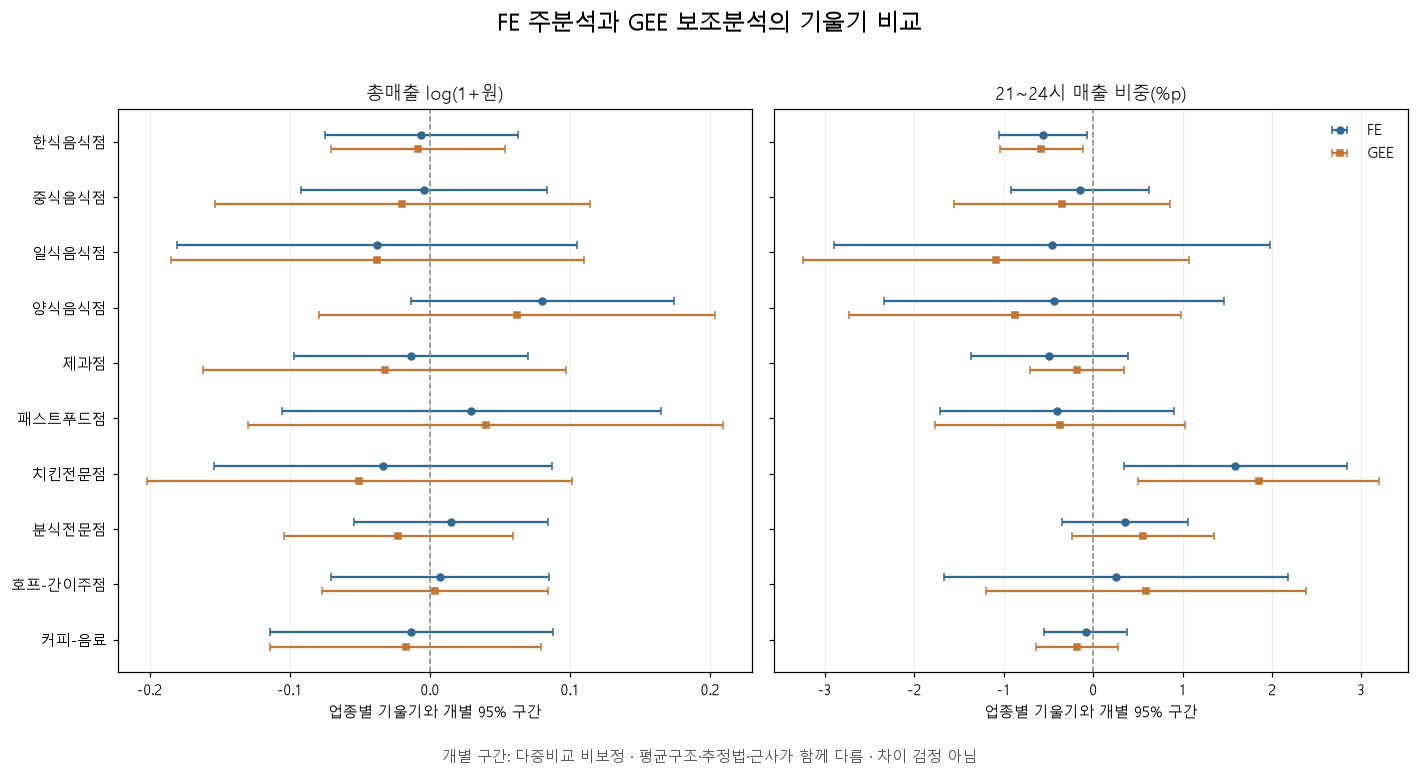

In [13]:
if not comparison.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 7.1), sharey=True)
    for ax, (outcome, title) in zip(axes, OUTCOMES.items()):
        part = comparison.loc[comparison['outcome'].eq(outcome)].set_index('industry_id').reindex(INDUSTRIES)
        for suffix, shift, color, marker in [('fe', -.13, '#326990', 'o'), ('gee', .13, '#C27736', 's')]:
            good = part[f'coefficient_{suffix}'].notna()
            ax.errorbar(part.loc[good, f'coefficient_{suffix}'], np.arange(10)[good]+shift,
                xerr=[(part.loc[good, f'coefficient_{suffix}']-part.loc[good, f'ci_low_{suffix}']).to_numpy(),
                      (part.loc[good, f'ci_high_{suffix}']-part.loc[good, f'coefficient_{suffix}']).to_numpy()],
                fmt=marker, color=color, capsize=2.5, markersize=4.5, label=suffix.upper())
        ax.axvline(0, color='#8A8A8A', linestyle='--', linewidth=1)
        ax.set_title(title); ax.set_xlabel('업종별 기울기와 개별 95% 구간')
        ax.set_yticks(range(10), [LABELS[item] for item in INDUSTRIES]); ax.grid(axis='x', alpha=.2)
    axes[0].invert_yaxis(); axes[1].legend(loc='best', frameon=False)
    fig.suptitle('FE 주분석과 GEE 보조분석의 기울기 비교', fontsize=15)
    fig.text(.5, .018, '개별 구간: 다중비교 비보정 · 평균구조·추정법·근사가 함께 다름 · 차이 검정 아님',
             ha='center', color='#555555')
    fig.tight_layout(rect=[0, .05, 1, .96])
    fig.savefig(FIGURES / '10_fe_gee_coefficients.png', dpi=160, bbox_inches='tight')
    plt.show(); plt.close(fig)

**비교 해석:** FE와 GEE의 부호·크기가 비슷하면 두 평균구조에서 유사한 관계가 관측되었다고만 말할 수 있다. 서로 다르면 평균구조·표본 구성·가중 및 상관 가정에 민감할 수 있다. 구간 겹침 여부만으로 두 계수의 차이가 유의한지 판단하지 않는다. 관측 수 일치는 관측 키의 완전한 일치까지 보장하지 않으므로 아래 저장한 표본 명세로 대조할 수 있다.

## 7. 한계와 기록
- 분석 반경에 실제로 기여하는 공연의 공식 ID·임시 연결 수는 최종 04번 연결 검증표로 확인한다. 서울 전체 목록의 잔여 임시 연결을 연구 표본의 임시 연결로 혼동하지 않으며, 공식 ID 확인이 목록 밖 공연까지 포괄함을 뜻하지는 않는다.
- 현재 목록의 좌표 확보 현황을 최종 03번 감사에서 확인한다. 좌표 확보율이 100%여도 과거 시설 이전·폐관 이력과 목록 밖 공연을 검증한 것은 아니며, 알려진 공연 수 0은 실제 공연 활동의 완전한 부재를 뜻하지 않는다. 최종 04번 노출은 최종 02번에서 검증한 최신 로컬 상세 스냅샷을 사용한다.
- 공연장 좌표 점에서 현재 상권 폴리곤까지의 최단거리가 500m 이내인 공연을 연결한다. 이 거리는 2023~2025년 당시 경계, 실제 이동 거리, 공연장 출입구 또는 개별 점포까지의 거리를 정확히 나타내지 않는다.
- 매출은 공개된 분기 추정매출이다. 누락은 0원이 아니며 결과는 일별 매출·일별 공연 반응을 설명하지 않는다. 상권×업종의 전체점포 수가 적은 집단에 매출 미제공이 집중되고 업종마다 관측 상권이 달라, 관측 결과를 전체 외식업으로 일반화할 수 없다.
- 지역 내 시간 변화가 매출의 원인이라는 식별 전략이 없다. 지역 이벤트·관광·경기·점포 구성과 공연 활동의 동시 변화, 역인과 및 상권 간 공간 상관이 남는다.
- 독립 공간 감사의 500m 노출에서 같은 공연×분기 ID는 평균 7.28개 상권에 공유되었다. 노출 공유는 잔차 공간 상관의 검증을 대신하지 않는다. FE에서 일부 업종은 상위 5개 상권에 공연 활동 정보의 절반 이상이 집중되었으며 명목 군집 수만으로 추론의 안정성을 보장할 수 없다.
- GEE의 exchangeable 작업상관은 모든 업종·분기 쌍에 같은 α를 가정한다. 상권 군집 robust 오차는 평균구조 오류나 상권 간 의존을 해결하지 않는다.
- 두 업종의 선행 결과를 확인한 뒤 전체 10종으로 확장했다. 본 결과는 탐색적이며 새로운 자료에서 재검증해야 한다. 유의성에 따라 업종·거리·추정법을 선택하지 않는다.

수치와 한계의 출처를 구분하기 위해 입력 해시·패키지 버전·표본 키·진단을 저장한다. 아래 연결 감사의 숫자는 최종 03번 산출물 시점의 기술 통계다. 최종 04번과 03번이 동일한 KOPIS 수집 스냅샷을 사용했는지 확인한다.

In [14]:
scope_metadata = json.loads((REPORTS / '08_food_scope_metadata.json').read_text(encoding='utf-8'))
audit_metadata = json.loads((REPORTS / '04_audit_summary.json').read_text(encoding='utf-8'))
assert scope_metadata['panel_sha256'] == hashlib.sha256(INPUT.read_bytes()).hexdigest()
assert scope_metadata['exposure_snapshot_linkage']['collection_run_id'] == audit_metadata['collection_run_id']
linkage_audit = REPORTS / '04_link_methods.csv'
coordinate_audit = REPORTS / '04_missing_coordinates_by_quarter.csv'
if linkage_audit.exists():
    display(pd.read_csv(linkage_audit))
if coordinate_audit.exists():
    coordinate = pd.read_csv(coordinate_audit)
    display(coordinate.groupby('district').agg(
        min_missing_pct=('missing_pct', 'min'), max_missing_pct=('missing_pct', 'max'),
        missing_performance_quarter_records=('missing_coordinate_performances', 'sum')))

,link_method,performance_ids,with_coordinates,facilities,share_pct
0,exact_unique_name,16320,16320,501,54.3149
1,official_detail,13727,13727,537,45.6851


,min_missing_pct,max_missing_pct,missing_performance_quarter_records
district,,,
마포구,0.0000,0.0000,0
종로구,0.0000,0.0000,0


**출처 해석:** 분기별 좌표 누락 수의 합은 공연×분기 건수이므로 고유 공연 수와 다르다. 위 감사 표는 공식 ID 연결과 이름 임시 연결의 구성 및 현재 시설 위치의 사용 범위를 보여 준다. 이 분석은 좌표 누락 보정이나 시설명 임시 연결의 확정 작업을 수행하지 않는다.

유의하지 않은 결과는 효과가 없다는 결론이 아니다. 개별 신뢰구간의 폭과 가능한 관계의 범위를 함께 보고한다.

In [15]:
from statsmodels.genmod.generalized_estimating_equations import GEE
source = inspect.getsource(GEE._covmat)
implementation_checks = pd.DataFrame([
    dict(check='gaussian_identity', passed=all(isinstance(fit.model.family, sm.families.Gaussian)
        and isinstance(fit.model.family.link, sm.families.links.Identity) for fit in models.values())),
    dict(check='exchangeable', passed=all(isinstance(fit.cov_struct, sm.cov_struct.Exchangeable)
        for fit in models.values())),
    dict(check='robust_covariance', passed=all(fit.cov_type == 'robust' for fit in models.values())),
    dict(check='area_is_group', passed=all(np.array_equal(fit.model.groups, frames[outcome]['area_id'].to_numpy())
        for outcome, fit in models.items())),
    dict(check='source_cluster_score_outer_products', passed=('range(self.num_group)' in source
        and 'np.outer(dvinv_resid, dvinv_resid)' in source)),
    dict(check='input_hashes_unchanged', passed=all(hashlib.sha256((ROOT/path).read_bytes()).hexdigest() == value
        for path, value in input_hashes.items())),
    dict(check='all_20_eligibility_records', passed=len(eligibility) == 20),
    dict(check='all_20_within_records', passed=len(within) == 20),
])
assert implementation_checks['passed'].all()
assert len(models) == int(diagnostics['accepted'].sum())
membership = pd.concat([frame[KEY + ['entity', 'log_activity', 'within_activity', 'between_activity']]
    .assign(outcome=outcome) for outcome, frame in frames.items() if not frame.empty], ignore_index=True)
display(implementation_checks)

,check,passed
0,gaussian_identity,True
1,exchangeable,True
2,robust_covariance,True
3,area_is_group,True
4,source_cluster_score_outer_products,True
5,input_hashes_unchanged,True
6,all_20_eligibility_records,True
7,all_20_within_records,True


**구현 확인:** 설치된 statsmodels의 `_covmat` 소스에서 군집별 score 외적을 합산하는 robust 공분산 구현을 확인했다. 위 점검은 지정한 모형·군집·표본·입력이 실제 계산에 사용되었는지 확인하는 절차이며 모형의 실질적 타당성을 보장하는 검정이 아니다. 실패 모형을 보고하지 않는 규칙은 별도로 수용 진단에 기록된다.

In [16]:
exports = {
    '10_gee_industry_effects.csv': within, '10_gee_between_effects.csv': between,
    '10_gee_eligibility.csv': eligibility, '10_gee_sample_flow.csv': sample_flow,
    '10_gee_sample_membership.csv': membership, '10_gee_diagnostics.csv': diagnostics,
    '10_gee_decomposition_checks.csv': pd.DataFrame(decomposition_rows),
    '10_gee_implementation_checks.csv': implementation_checks,
}
if not fe_key_checks.empty:
    exports['10_fe_gee_sample_key_checks.csv'] = fe_key_checks
if not comparison.empty:
    exports['10_fe_gee_comparison.csv'] = comparison
for filename, table in exports.items():
    table.to_csv(REPORTS / filename, index=False, encoding='utf-8-sig')
scope_metadata = json.loads((REPORTS / '08_food_scope_metadata.json').read_text(encoding='utf-8'))
summary = dict(seoul_refresh_run_id=scope_metadata.get('seoul_refresh_run_id'),
    kopis_collection_run_id=scope_metadata['exposure_snapshot_linkage'].get('collection_run_id'),
    scope='종로구·마포구 / 공개자료 외식업 10종 / 2023~2025 분기',
    exploratory_expansion_after_two_industry_results=True, radius_m=500,
    input_sha256=input_hashes, accepted_gee_models=len(models), planned_gee_models=len(OUTCOMES),
    eligible_industry_outcomes=int(eligibility['eligible'].sum()), planned_industry_outcomes=20,
    exploratory_bh_family_size=20, family='Gaussian', link='identity', covariance_structure='exchangeable',
    cluster='area_id', covariance_type='robust', confidence_interval='individual_normal_95pct_not_multiplicity_adjusted',
    between_mean='final_sample_entity_observed_mean', causal_identification=False,
    exact_paper_replication=False, fe_comparison_status=fe_comparison_status,
    fe_input_sha256=fe_input_sha256, fe_membership_sha256=fe_membership_sha256,
    exact_fe_gee_keys_match=(bool(fe_key_checks['exact_keys_match'].all()) if not fe_key_checks.empty else None),
    between_p_values_adjusted=False,
    python=platform.python_version(), packages={name: metadata.version(name)
        for name in ['pandas', 'numpy', 'scipy', 'statsmodels', 'matplotlib', 'nbformat']},
    limitations=['서울 전체 목록과 분석 반경의 연결 현황 구분', '현재 목록의 좌표 확보와 과거 위치 검증은 구분', '현재 상권 경계와 공연장 점–상권 폴리곤 최단거리',
                 '작은 점포 집단에 집중된 분기 추정매출 누락', '업종별 서로 다른 관측 상권', '일부 상권에 집중된 설명변수 정보', '공연 목록과 회차·관객 차이', '상권 간 공간 상관 미해결', '비유의 결과는 효과 부재의 증거가 아님',
                 'FE와 GEE의 평균구조 및 추론 차이', '관측 뒤 10종으로 확대한 탐색 분석'])
summary['output_sha256'] = {filename: hashlib.sha256((REPORTS/filename).read_bytes()).hexdigest()
                            for filename in exports}
(REPORTS / '10_gee_analysis_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

2903

## 8. 결과 읽기
아래 문장은 저장한 결과표에서 자동 생성된다. 통계적으로 뚜렷한 관계를 발견하지 못한 경우에도 계수와 구간을 함께 읽어 효과의 가능한 범위를 확인해야 한다. GEE 보조 결과로 FE 주분석의 결론을 대체하거나 공연 활성화 정책의 인과적 효과를 주장하지 않는다.

In [17]:
lines = [f"- 수치 수용 조건을 통과한 GEE: **{len(models)}/2개**.",
         f"- 최소 표본·변동 기준을 충족한 업종×결과: **{int(eligibility['eligible'].sum())}/20개**.",
         f'- FE 비교: {fe_comparison_status}.']
for outcome, label in OUTCOMES.items():
    part = within.loc[within['outcome'].eq(outcome)]
    positive = part.loc[part['p_fdr_gee_exploratory'].lt(.05) & part['coefficient'].gt(0), 'industry'].tolist()
    negative = part.loc[part['p_fdr_gee_exploratory'].lt(.05) & part['coefficient'].lt(0), 'industry'].tolist()
    lines.append(f"- {label}: GEE 내부 탐색적 BH p<.05인 양의 관계 {', '.join(positive) or '없음'}, "
                 f"음의 관계 {', '.join(negative) or '없음'}. 확인적 결론이나 업종 간 차이 검정이 아니다.")
display(Markdown('\n'.join(lines)))

- 수치 수용 조건을 통과한 GEE: **2/2개**.
- 최소 표본·변동 기준을 충족한 업종×결과: **20/20개**.
- FE 비교: FE와 GEE의 20개 업종·결과 비교 완료.
- 총매출 log(1+원): GEE 내부 탐색적 BH p<.05인 양의 관계 없음, 음의 관계 없음. 확인적 결론이나 업종 간 차이 검정이 아니다.
- 21~24시 매출 비중(%p): GEE 내부 탐색적 BH p<.05인 양의 관계 없음, 음의 관계 없음. 확인적 결론이나 업종 간 차이 검정이 아니다.

## 최종 정리 전후의 주분석 계산 검증
코드와 경로를 정리하기 직전의 주분석 결과를 `metadata/main/statistics_reference/`에 고정했다. 같은 입력 스냅샷에서 업종·결과별 계수, 표준오차, 개별 신뢰구간, p값과 관측 수가 보존되었는지 대조한다. 이 검증은 계산의 재현성을 확인하며, 해석상의 한계나 관측자료의 선택 문제를 해결하지 않는다.

In [18]:
reference_dir = ROOT / 'metadata/main/statistics_reference'
reference_manifest = json.loads((reference_dir / 'manifest.json').read_text(encoding='utf-8'))
reference_path = reference_dir / '10_gee_industry_effects.csv'
reference_sha256 = hashlib.sha256(reference_path.read_bytes()).hexdigest()
assert reference_sha256 == reference_manifest['files']['10_gee_industry_effects.csv']['sha256']
reference_results = pd.read_csv(reference_path, dtype={'industry_id': str})
final_results = pd.read_csv(REPORTS / '10_gee_industry_effects.csv', dtype={'industry_id': str})
check_keys = ['scenario', 'outcome', 'industry_id']
check_values = ['coefficient', 'standard_error', 'ci_low', 'ci_high', 'p_value',
                'nobs_industry', 'area_clusters_industry']
left = reference_results.loc[reference_results['scenario'].eq('gee_within_between_500'), check_keys + check_values]
right = final_results.loc[final_results['scenario'].eq('gee_within_between_500'), check_keys + check_values]
comparison_check = left.merge(right, on=check_keys, how='outer', validate='one_to_one',
                              suffixes=('_reference', '_final'), indicator=True)
assert len(comparison_check) == 20 and comparison_check['_merge'].eq('both').all()
max_errors = {name: float((comparison_check[name + '_reference'] - comparison_check[name + '_final']).abs().max())
              for name in check_values}
assert all(value < 1e-10 for value in max_errors.values()), max_errors
receipt = dict(check='final_vs_frozen_prior_primary_results', scenario='gee_within_between_500',
    compared_industry_outcomes=len(comparison_check), absolute_tolerance=1e-10, passed=True,
    reference_file=reference_path.relative_to(ROOT).as_posix(), reference_sha256=reference_sha256,
    final_file=(REPORTS / '10_gee_industry_effects.csv').relative_to(ROOT).as_posix(),
    final_sha256=hashlib.sha256((REPORTS / '10_gee_industry_effects.csv').read_bytes()).hexdigest(),
    max_absolute_difference_by_column=max_errors)
(REPORTS / '06_prior_primary_reproducibility.json').write_text(
    json.dumps(receipt, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
display(pd.DataFrame([max_errors]).rename(index={0:'정리 전후 주분석 최대 절대오차'}))

,coefficient,standard_error,ci_low,ci_high,p_value,nobs_industry,area_clusters_industry
정리 전후 주분석 최대 절대오차,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
